# ЛР 2. Логистическая и линейная регрессии

## Данные

Avila. По 10 признакам фрагмента текста предсказываем одного из 12 переписчиков. Это помогает распределять фрагменты перед ручной проверкой. Используем разбиение UCI и три стратифицированных фолда в обучающей части. [Источник](https://doi.org/10.24432/C5K02X)

Tasmania. По координатам 16 преобразователей предсказываем мощность фермы. Это позволяет отбирать конфигурации перед запуском симулятора. Мощности отдельных преобразователей исключаем, поскольку их сумма практически равна цели. Берем 7200 конфигураций. Раскладки с одинаковыми координатами после округления до 10 м попадают в одну группу. Группы разделяем между обучением и тестом. В обучающей части три групповых фолда. [Источник](https://doi.org/10.24432/C5831S)

In [1]:
import pandas as pd
from IPython.display import display
from labkit.data import load_tasks
from labkit.experiments import (
    comparison_text, describe_data, evaluate_holdout, plot_predictions,
    plot_training, primary_metric, save_scores, select_candidates,
)

LAB = 2
tasks = load_tasks()
display(describe_data(tasks))
for task in tasks:
    display(pd.Series(task.audit, name=task.title).to_frame())

,задача,строк в исходных файлах,train,test,исходные признаки,разбиение
0,Avila,20867,10430,10437,10,"Разбиение UCI, 3 стратифицированных фолда на t..."
1,Tasmania,72000,5762,1438,32,"20% групп на тесте, 3 групповых фолда на train."


,Avila
Точных совпадений векторов признаков между train/test,0


,Tasmania
Строк после проверки диапазонов и пропусков,72000
Точных уникальных конфигураций,72000
Строк в воспроизводимой подвыборке,7200
Групп в подвыборке (округление координат до 10 м),7183


## Метрики

Avila. Macro-F1 дает одинаковый вес каждому классу. Balanced accuracy усредняет полноту по классам. Accuracy показывает общую долю верных ответов.

Tasmania. MAE показывает средний промах в МВт. RMSE сильнее учитывает крупные ошибки. R² сравнивает модель с прогнозом среднего.

Для сравнения простая модель предсказывает самый частый класс или медианную мощность из обучающей выборки.

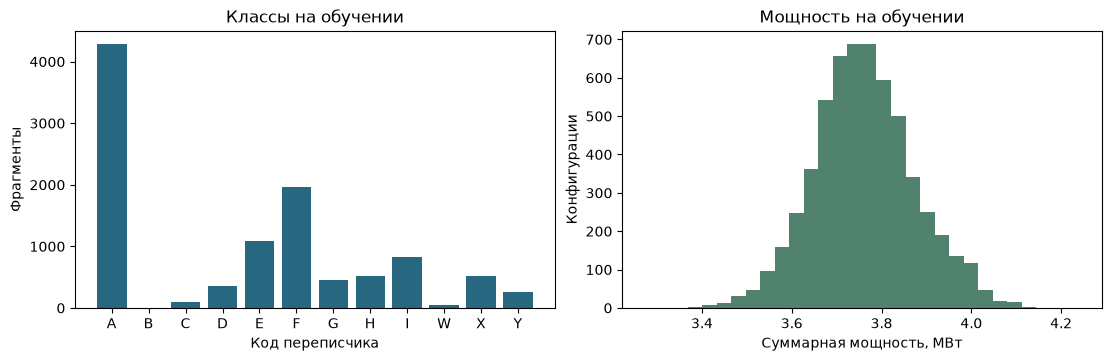

In [2]:
plot_training(tasks)

## Бейзлайн sklearn

Логистическая регрессия sklearn использует мультиномиальную log-loss, L2-регуляризацию и C=1. Линейная регрессия использует метод наименьших квадратов со свободным членом.

## Подбор параметров

Для Avila проверяем веса классов, C=0.3 и квадратичные признаки. Веса усиливают вклад редких классов, а произведения признаков дают нелинейную границу. Для Tasmania проверяем геометрические признаки, квадратичные взаимодействия и Ridge. Регуляризация ограничивает рост коэффициентов.

Выбор по среднему macro-F1 или MAE на трех фолдах. Масштабирование обучается внутри каждого фолда. При равенстве оценок берем первый вариант.

In [3]:
selections = select_candidates(LAB, tasks)
for task in tasks:
    print(f"{task.title} ({primary_metric(task)})")
    display(selections[task.key][2].round(5))

Avila (macro_f1)


,гипотеза,признаки,настройки,CV среднее,CV std,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.40776,0.02168,0.38641,0.40711,0.42975,False
1,Взвешивание редких классов,raw,"{""class_weight"": ""balanced""}",0.43066,0.00788,0.43525,0.42156,0.43516,False
2,Стандартизация и C=0.3,standard,"{""C"": 0.3}",0.34324,0.04984,0.29754,0.39639,0.33580,False
3,Квадратичные признаки и C=0.3,polynomial,"{""C"": 0.3}",0.57109,0.02057,0.54772,0.57904,0.58649,False
4,Квадратичные признаки и веса классов,polynomial,"{""C"": 0.3, ""class_weight"": ""balanced""}",0.57747,0.01708,0.55835,0.59121,0.58284,True


Tasmania (mae_mw)


,гипотеза,признаки,настройки,CV среднее,CV std,фолд 1,фолд 2,фолд 3,выбран
0,Бейзлайн,raw,{},0.08153,0.00072,0.08227,0.08150,0.08083,False
1,Геометрия,geometry,{},0.05999,0.00023,0.05983,0.06025,0.05989,False
2,Геометрия и Ridge,geometry_standard,"{""alpha"": 10.0}",0.06048,0.00028,0.06054,0.06073,0.06018,False
3,Квадратичные признаки координат и Ridge,polynomial,"{""alpha"": 10.0}",0.04935,0.00076,0.04861,0.05012,0.04932,True
4,Квадратичные признаки геометрии и Ridge,geometry_polynomial,"{""alpha"": 10.0}",0.05170,0.00083,0.05105,0.05264,0.05142,False


## Результаты sklearn

Начальную и выбранную модели обучаем на всей обучающей выборке и проверяем на тесте.

In [4]:
results = evaluate_holdout(LAB, tasks, selections)
for task in tasks:
    table, _ = results[task.key]
    base = table.loc[table["version"].isin(["dummy", "sklearn baseline", "sklearn tuned"])]
    print(task.title)
    display(base.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

Avila


,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
0,dummy,Мода,NaN,NaN,0.04852,0.08333,0.41065
1,sklearn baseline,Бейзлайн,2.85324,0.00622,0.39651,0.39430,0.56146
2,sklearn tuned,Квадратичные признаки и веса классов,2.88232,0.07548,0.58688,0.72814,0.56721


Tasmania


,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
0,dummy,Медиана,NaN,NaN,0.08752,0.11228,-0.00000
1,sklearn baseline,Бейзлайн,0.02567,0.00267,0.08134,0.10510,0.12379
2,sklearn tuned,Квадратичные признаки координат и Ridge,0.87582,0.06231,0.04799,0.06213,0.69378


## Своя реализация

В логистической регрессии вычисляем log-loss и градиент вручную. Коэффициенты обновляет L-BFGS из SciPy. В линейной регрессии центрируем признаки и отклик, решаем задачу МНК и восстанавливаем свободный член. Для Ridge добавляем L2-штраф к коэффициентам.

Для обеих версий используем те же настройки и признаки, что у sklearn. [Код моделей](labkit/models.py)

In [5]:
for task in tasks:
    table, _ = results[task.key]
    models = table.loc[table["version"] != "dummy"]
    print(task.title)
    display(models.dropna(axis=1, how="all").drop(columns=["lab", "task", "algorithm"]).round(5))

Avila


,version,candidate,fit_s,predict_s,macro_f1,balanced_accuracy,accuracy
1,sklearn baseline,Бейзлайн,2.85324,0.00622,0.39651,0.39430,0.56146
2,sklearn tuned,Квадратичные признаки и веса классов,2.88232,0.07548,0.58688,0.72814,0.56721
3,own baseline,Бейзлайн,23.55960,0.00937,0.39656,0.39425,0.56137
4,own tuned,Квадратичные признаки и веса классов,12.93920,0.07630,0.58776,0.73014,0.56760


Tasmania


,version,candidate,fit_s,predict_s,mae_mw,rmse_mw,r2
1,sklearn baseline,Бейзлайн,0.02567,0.00267,0.08134,0.10510,0.12379
2,sklearn tuned,Квадратичные признаки координат и Ridge,0.87582,0.06231,0.04799,0.06213,0.69378
3,own baseline,Бейзлайн,0.01521,0.00105,0.08134,0.10510,0.12379
4,own tuned,Квадратичные признаки координат и Ridge,1.68349,0.05503,0.04799,0.06213,0.69378


## Ошибки на тесте

Графики для настроенных моделей sklearn. Строки матрицы ошибок показывают доли по истинному классу. Пунктир на графике мощности показывает идеальный прогноз.

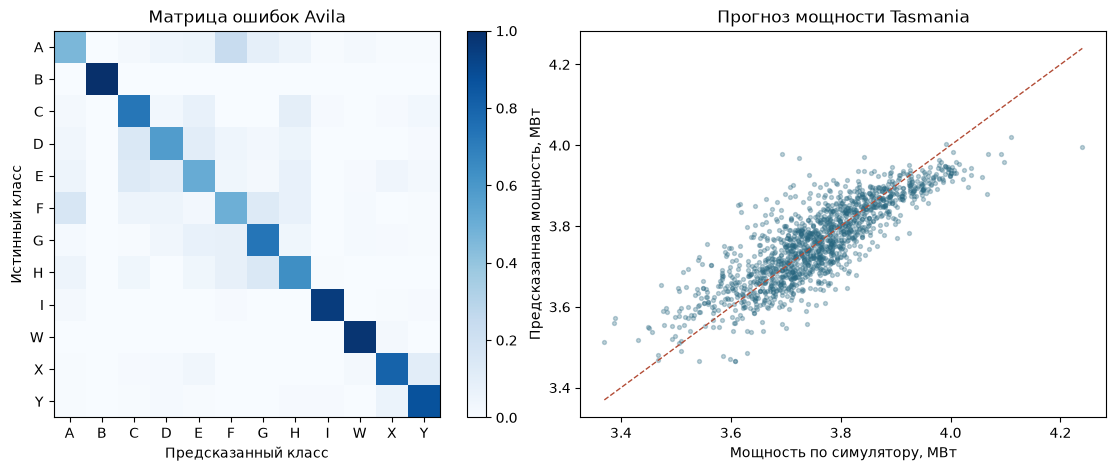

In [6]:
plot_predictions(tasks, results)

## Выводы

In [7]:
print(comparison_text(tasks, results, selections))
relative_path = save_scores(LAB, results)
print(f"Метрики сохранены в {relative_path.as_posix()}")

Avila (macro-F1)
По кросс-валидации выбран вариант «Квадратичные признаки и веса классов».
Среднее на фолдах: 0.4078 до настройки и 0.5775 после.
Sklearn на тесте: 0.3965 до настройки и 0.5869 после.
Своя модель на тесте: 0.3966 до настройки и 0.5878 после.
Разница со sklearn на тесте: +0.0001 до настройки и +0.0009 после.

Tasmania (MAE, МВт)
По кросс-валидации выбран вариант «Квадратичные признаки координат и Ridge».
Среднее на фолдах: 0.0815 до настройки и 0.0494 после.
Sklearn на тесте: 0.0813 до настройки и 0.0480 после.
Своя модель на тесте: 0.0813 до настройки и 0.0480 после.
Разница со sklearn на тесте: +0.0000 до настройки и +0.0000 после.
Метрики сохранены в results/lab_02.csv
